In [6]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
#import scikit-image as skimage

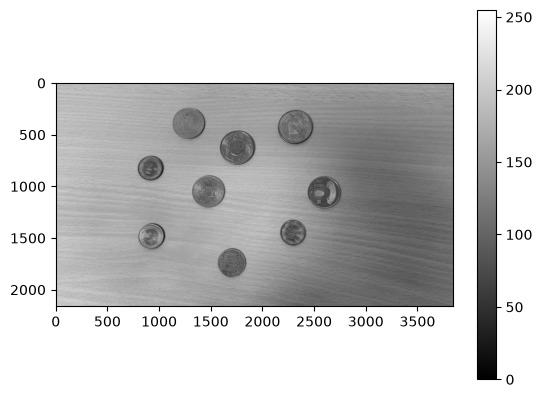

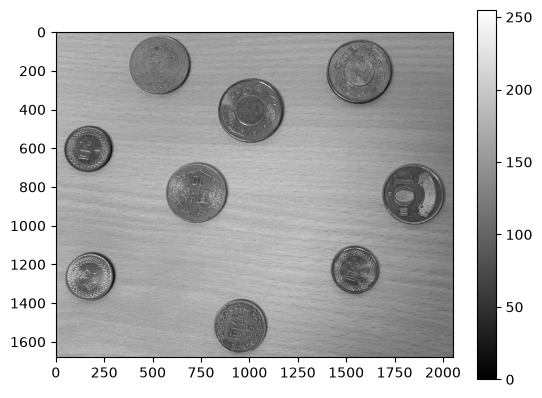

In [20]:
a = plt.imread('./data/image.jpg')
a_gris = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
plt.imshow(a_gris, cmap='gray')
plt.colorbar()
plt.show()

b_gris = a_gris[220:1900, 750:2800]
plt.imshow(b_gris, cmap='gray')
plt.colorbar()
plt.show()

cercle détecté : centre=(1015, 401), taille=326
cercle détecté : centre=(727, 823), taille=324
cercle détecté : centre=(953, 1514), taille=276
cercle détecté : centre=(1567, 209), taille=342
cercle détecté : centre=(535, 166), taille=316
cercle détecté : centre=(170, 602), taille=248
cercle détecté : centre=(1836, 842), taille=300
cercle détecté : centre=(1558, 1222), taille=232
cercle détecté : centre=(190, 1255), taille=238
9 cercles détectés


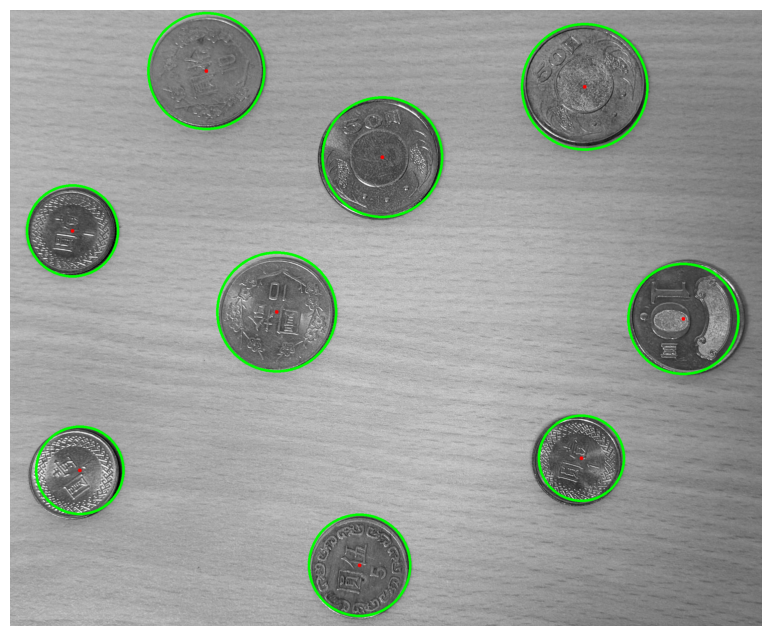

In [25]:
chemin = './data/image.jpg'
piece = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE) # on force l'image a rester en niveau de gris (car c'est plus simple pour detecter les cercles)
piece = piece[220:1900, 750:2800] # on recadre jsp si c'est vrm utile
echelle = 0.25
piece_reduite = cv2.resize(piece, None, fx=echelle, fy=echelle, interpolation=cv2.INTER_AREA) # pour reduire la quelité pour que ça aille plus vite
piece_floue = cv2.medianBlur(piece_reduite, 5) # pour ne pas etre perturbé par certain détail (c'est juste pour la detection des cercles)
image_resultat = cv2.cvtColor(piece, cv2.COLOR_GRAY2RGB) # permet a la fin de pouvoir rajouter des couleurs sur l'image (car plus tot j'ai forcer l'image a rester en niveau de gris)

cercles = cv2.HoughCircles(
    piece_floue, # l'image sur la quel on cherche les cercles
    cv2.HOUGH_GRADIENT, # la methode
    dp=1.2, # a quel point ça dois etre un cercle parfait (1 c'est parfait, 1.2 ça peut être légeremnt oval)
    minDist=65, # la distance minimale entre 2 cercle, pour eviter de detecter 2 fois la mme piece
    param1=100, # plus c'est haut plus le contours doit etre net pour etre detecte
    param2=30, # le taux de fiabilité (plus c'est haut plus il a tendance a detecter des cercle)
    minRadius=25, # les limite de tailles des rayons des cercle
    maxRadius=60,
)

if piece is None:
    raise FileNotFoundError(f'Image introuvable : {chemin}')

if cercles is None:
    print('Aucun cercle détecté. Essaie de diminuer param2 ou ajuste minRadius/maxRadius.')
else:
    cercles = np.round(cercles[0] / echelle).astype(int)
    for x, y, rayon in cercles:
        cv2.circle(image_resultat, (x, y), rayon, (0, 255, 0), 5)
        cv2.circle(image_resultat, (x, y), 5, (255, 0, 0), -1)
        print(f'cercle détecté : centre=({x}, {y}), taille={rayon*2}')
    print(f'{len(cercles)} cercles détectés')

plt.figure(figsize=(14, 8))
plt.imshow(image_resultat)
plt.axis('off')
plt.show()

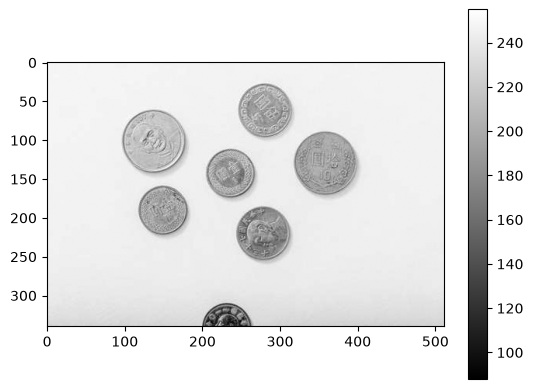

cercle détecté : centre=(199, 218), taille=72
cercle détecté : centre=(55, 103), taille=82
cercle détecté : centre=(199, 60), taille=72
cercle détecté : centre=(70, 190), taille=62
cercle détecté : centre=(156, 142), taille=66
cercle détecté : centre=(276, 127), taille=76
6 cercles détectés


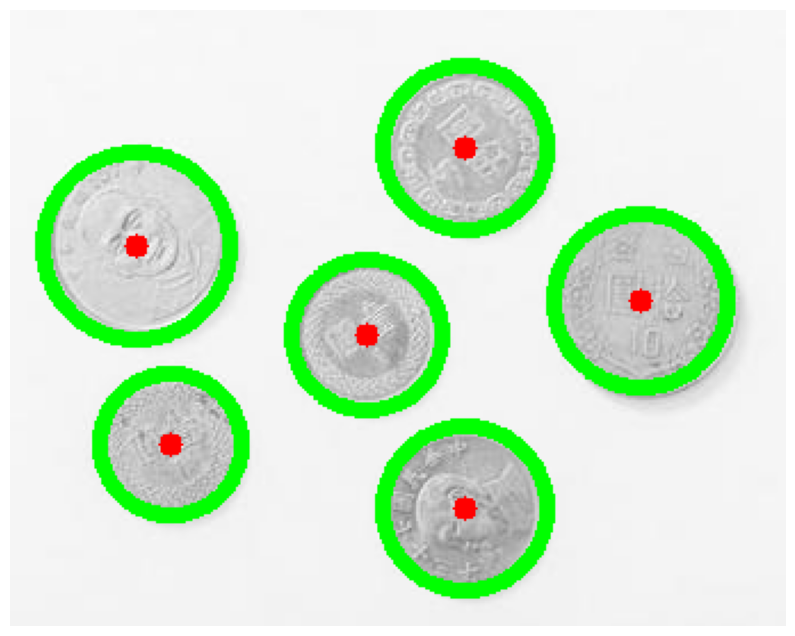

In [70]:
chemin = './data/43fef775db14373494f2246ff3754a16_t.jpg'

taille = plt.imread(chemin)
a_gris = cv2.cvtColor(taille, cv2.COLOR_RGB2GRAY)
plt.imshow(a_gris, cmap='gray')
plt.colorbar()
plt.show()

piece = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE) # on force l'image a rester en niveau de gris (car c'est plus simple pour detecter les cercles)
piece = piece[:270, 80:420] # on recadre jsp si c'est vrm utile
echelle = 0.25
piece_reduite = cv2.resize(piece, None, fx=echelle, fy=echelle, interpolation=cv2.INTER_AREA) # pour reduire la quelité pour que ça aille plus vite
piece_floue = cv2.medianBlur(piece_reduite, 5) # pour ne pas etre perturbé par certain détail (c'est juste pour la detection des cercles)
image_resultat = cv2.cvtColor(piece, cv2.COLOR_GRAY2RGB) # permet a la fin de pouvoir rajouter des couleurs sur l'image (car plus tot j'ai forcer l'image a rester en niveau de gris)

cercles = cv2.HoughCircles(
    piece_floue, # l'image sur la quel on cherche les cercles
    cv2.HOUGH_GRADIENT, # la methode
    dp=1.2, # a quel point ça dois etre un cercle parfait (1 c'est parfait, 1.2 ça peut être légeremnt oval)
    minDist=20, # la distance minimale entre 2 cercle, pour eviter de detecter 2 fois la mme piece
    param1=70, # plus c'est haut plus le contours doit etre net pour etre detecte
    param2=30, # le taux de fiabilité (plus c'est haut plus il a tendance a detecter des cercle)
    minRadius=0, # les limite de tailles des rayons des cercle
    maxRadius=20,
)

if piece is None:
    raise FileNotFoundError(f'Image introuvable : {chemin}')

if cercles is None:
    print('Aucun cercle détecté. Essaie de diminuer param2 ou ajuste minRadius/maxRadius.')
else:
    cercles = np.round(cercles[0] / echelle).astype(int)
    for x, y, rayon in cercles:
        cv2.circle(image_resultat, (x, y), rayon, (0, 255, 0), 5)
        cv2.circle(image_resultat, (x, y), 5, (255, 0, 0), -1)
        print(f'cercle détecté : centre=({x}, {y}), taille={rayon*2}')
    print(f'{len(cercles)} cercles détectés')

plt.figure(figsize=(14, 8))
plt.imshow(image_resultat)
plt.axis('off')
plt.show()